# 1. Import necessary packages

In [49]:
import os

import turmoric
from turmoric.image_process import nd2_to_tif
from turmoric.utils import recursively_get_all_filepaths
from turmoric.apply_thresholds import apply_all_thresh

from pathlib import Path

import pandas as pd
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import filters, io
from skimage.segmentation import clear_border
from skimage.morphology import remove_small_objects
from skimage.measure import block_reduce, label, regionprops, regionprops_table
from skimage import exposure
from scipy import ndimage

from turmoric.cell_analysis import apply_regionprops_recursively
from turmoric.utils import organize_files_without_leakage
from turmoric.vampire_model import VampireModelTrainer
from turmoric.split_functions import *
from turmoric.grouping_strategy import CustomFunctionStrategy


from PIL import Image

from sklearn.model_selection import train_test_split

import sklearn
import shutil
from typing import List, Dict, Callable, Optional, Any


import vampire
from vampire.plot import *

import matplotlib.pyplot as plt

import warnings
import logging

# Suppress matplotlib font warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)


import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold



In [8]:
all_tifs = recursively_get_all_filepaths("/gscratch/cheme/nlsschim/data/cross_species/tifs/all_data", file_type=".tif")
print(len(all_tifs))

2089


In [12]:
props_list = ('area', 'bbox_area', 'centroid', 'convex_area',
              'eccentricity', 'equivalent_diameter', 'euler_number',
              'extent', 'filled_area', 'major_axis_length',
              'minor_axis_length', 'orientation', 'perimeter', 'solidity',
              'feret_diameter_max')

In [46]:
regionprops_dfs = []

for file in all_tifs:
    im = tiff.imread(file)

    label_im = label(im)
    props = regionprops_table(label_im, properties=props_list)

    props_df = pd.DataFrame(props)
    props_df['filename'] = file

    species = file.split("/")[8]

    props_df['species'] = species
    regionprops_dfs.append(props_df)

all_regionprops_data = pd.concat(regionprops_dfs)

In [51]:
# regionprops_df = apply_regionprops_recursively(input_folder="/gscratch/cheme/nlsschim/data/cross_species/tifs/all_data/", 
#                                                properties_list=props_list)
all_regionprops_data['circularity'] = 4*np.pi*all_regionprops_data.area/all_regionprops_data.perimeter**2
all_regionprops_data['aspect_ratio'] = all_regionprops_data.major_axis_length/all_regionprops_data.minor_axis_length
all_regionprops_data

,area,bbox_area,centroid-0,centroid-1,convex_area,eccentricity,equivalent_diameter,euler_number,extent,filled_area,major_axis_length,minor_axis_length,orientation,perimeter,solidity,feret_diameter_max,filename,species,circularity,aspect_ratio
0,274.0,621.0,16.324818,227.656934,357.0,0.921304,18.677999,1,0.441224,274.0,33.063717,12.856610,0.950213,89.533009,0.767507,31.622777,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.429531,2.571729
1,504.0,2100.0,52.299603,473.992063,1315.0,0.766841,25.332049,1,0.240000,504.0,47.182152,30.283230,-0.509399,217.373629,0.383270,55.036352,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.134038,1.558029
2,180.0,1470.0,50.272222,82.800000,894.0,0.714918,15.138795,1,0.122449,180.0,44.894815,31.390850,1.044337,133.390873,0.201342,45.177428,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.127125,1.430188
3,136.0,357.0,62.977941,441.639706,180.0,0.928692,13.159049,1,0.380952,136.0,25.039561,9.285995,0.659676,62.183766,0.755556,23.706539,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.441972,2.696487
4,325.0,874.0,110.058462,302.640000,576.0,0.926769,20.342145,1,0.371854,325.0,38.176078,14.340164,0.106594,126.811183,0.564236,46.097722,/gscratch/cheme/nlsschim/data/cross_species/ti...,human,0.253967,2.662179
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38,192.0,1155.0,467.593750,376.130208,655.0,0.721915,15.635280,1,0.166234,192.0,37.887680,26.217587,0.751143,127.290368,0.293130,36.400549,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.148909,1.445125
39,222.0,750.0,463.171171,148.864865,604.0,0.676913,16.812471,1,0.296000,222.0,33.128086,24.384375,0.708160,164.876154,0.367550,36.235342,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.102624,1.358578
40,343.0,1224.0,466.373178,114.559767,817.0,0.699378,20.897875,1,0.280229,343.0,36.409432,26.023722,-0.576198,168.053824,0.419829,37.735925,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.152619,1.399086
41,200.0,1000.0,473.405000,35.160000,642.0,0.937682,15.957691,1,0.200000,200.0,46.585316,16.188093,-0.278226,150.118795,0.311526,42.059482,/gscratch/cheme/nlsschim/data/cross_species/ti...,rat,0.111524,2.877752


In [22]:
medians = all_regionprops_data[["area", "bbox_area", "convex_area", "perimeter", "extent", "solidity", "circularity", "aspect_ratio", "eccentricity"]].median()
medians

area             247.000000
bbox_area       1104.000000
convex_area      644.000000
perimeter        141.604076
extent             0.227119
solidity           0.378866
circularity        0.141169
aspect_ratio       2.089493
eccentricity       0.878041
dtype: float64

In [52]:
all_regionprops_data.to_csv("all_species_data.csv", index=False)

In [5]:
all_regionprops_data = pd.read_csv("all_species_data.csv")

In [6]:
morphology_features = ['area', 'bbox_area', 'convex_area',
              'eccentricity', 'equivalent_diameter', 'euler_number',
              'extent', 'filled_area', 'major_axis_length',
              'minor_axis_length', 'orientation', 'perimeter', 'solidity',
              'feret_diameter_max', 'circularity', 'aspect_ratio']

In [2]:
# Define your base directory and target directories for training and testing
base_dir = "/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm"
train_dir = "/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/training"
test_dir = "/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/testing"

# Define a list of subfolder names or patterns to look for
treatment_conditions = ["cortex", "corpus_col"]
groups = ["human_female", "human_male",  "mice_female",  "mice_male",  "pig_female",  "rat_female",  "rat_male"]
#groups = ["human_female"]

# Create training and testing directories if they don't exist
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

In [3]:
image_set_path = train_dir

train_properties_df = vampire.extraction.extract_properties(img_set_path=image_set_path)

Contour and properties data already exist in path: /gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/training
Contour and properties data already exist in path: /gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/training


In [6]:
build_info_df = pd.DataFrame({
    'img_set_path': [image_set_path],
    'output_path': [image_set_path],
    'model_name': ['li'],
    'num_points': [50],
    'num_clusters': [5],
    'num_pc': [np.nan]
})

In [ ]:
vampire.quickstart.fit_models(build_info_df)

In [8]:
model_path = os.path.join(image_set_path, 'model_li_(50_5_25)__.pickle')
vampire_model = vampire.util.read_pickle(model_path)

In [4]:
groups = ["human_female", "human_male",  "mice_female",  "mice_male",  "pig_female",  "rat_female",  "rat_male"]

In [42]:
from pathlib import Path

base_path = Path("/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/")

# Find ALL .tif files recursively
all_files = list(base_path.rglob("*.tif"))

print(f"Total .tif files found: {len(all_files)}")
print(f"\nFirst 5 files:")
for f in all_files[:5]:
    print(f"  {f.relative_to(base_path)}")

print(f"\nLast 5 files:")
for f in all_files[-5:]:
    print(f"  {f.relative_to(base_path)}")

Total .tif files found: 257

First 5 files:
  mice_male/corpus_col/20230203_mouse_saline_p45_ms6_slide9_slice3_60x_cc2_denoised_Alexa_488_antibody_otsu_thresh.tif
  mice_male/corpus_col/20230203_mouse_saline_p45_ms6_slide9_slice3_60x_cc1_denoised_Alexa_488_antibody_otsu_thresh.tif
  mice_male/corpus_col/20230205_mouse_saline_p45_ms5_slide14_slice3_60x_cc1_denoised_Alexa_488_antibody_otsu_thresh.tif
  mice_male/corpus_col/20230212_mouse_saline_p45_ms4_slide14_slice_slice2_60x_cc2_denoised_Alexa_488_antibody_otsu_thresh.tif
  mice_male/corpus_col/20230206_mouse_saline_p45_ms5_slide14_slice4_60x_cc1_denoised_Alexa_488_antibody_otsu_thresh.tif

Last 5 files:
  pig_female/cortex/20230312_pig_sow2_D_slide7_60x_denoised_cor1_Alx568_otsu_thresh.tif
  pig_female/cortex/20230315_pig_sow1_B_60x_denoised_cor3_Alx568_otsu_thresh.tif
  pig_female/cortex/20230315_pig_sow2_B_60x_denoised_cor2_Alx568_otsu_thresh.tif
  pig_female/cortex/20230312_pig_sow1_D_slide8_60x_denoised_cor2_Alx568_otsu_thresh.tif

In [43]:
from pathlib import Path

base_path = Path("/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/")
all_files = list(base_path.rglob("*.tif"))

# Each file is its own "group"
groups = {f.stem: [f] for f in all_files}

print(f"Total files (groups): {len(groups)}")
print(f"\nFirst 5:")
for i, (group_id, files) in enumerate(list(groups.items())[:5]):
    print(f"  {group_id}")

Total files (groups): 257

First 5:
  20230203_mouse_saline_p45_ms6_slide9_slice3_60x_cc2_denoised_Alexa_488_antibody_otsu_thresh
  20230203_mouse_saline_p45_ms6_slide9_slice3_60x_cc1_denoised_Alexa_488_antibody_otsu_thresh
  20230205_mouse_saline_p45_ms5_slide14_slice3_60x_cc1_denoised_Alexa_488_antibody_otsu_thresh
  20230212_mouse_saline_p45_ms4_slide14_slice_slice2_60x_cc2_denoised_Alexa_488_antibody_otsu_thresh
  20230206_mouse_saline_p45_ms5_slide14_slice4_60x_cc1_denoised_Alexa_488_antibody_otsu_thresh


In [44]:
from pathlib import Path
import random

base_path = Path("/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/")
all_files = list(base_path.rglob("*.tif"))

# Shuffle files for random splits
random.seed(42)
shuffled_files = all_files.copy()
random.shuffle(shuffled_files)

# Split into 5 folds
k = 5
fold_size = len(shuffled_files) // k
folds = []

for i in range(k):
    start = i * fold_size
    end = start + fold_size if i < k - 1 else len(shuffled_files)
    folds.append(shuffled_files[start:end])

print(f"Total files: {len(shuffled_files)}")
print(f"Number of folds: {len(folds)}")
print(f"Fold sizes: {[len(f) for f in folds]}")

# Show what fold 0 looks like
print(f"\nFold 0 (first 3 files):")
for f in folds[0][:3]:
    print(f"  {f.name}")

# Create train/test splits
print(f"\nTrain/test splits:")
for i in range(k):
    test = folds[i]
    train = [f for j, fold in enumerate(folds) if j != i for f in fold]
    print(f"Fold {i}: {len(train)} train, {len(test)} test")

Total files: 257
Number of folds: 5
Fold sizes: [51, 51, 51, 51, 53]

Fold 0 (first 3 files):
  20230315_pig_sow2_B_60x_cc3_denoised_Alx568_otsu_thresh.tif
  20230203_mouse_saline_p45_ms6_slide9_slice3_60x_cc3_denoised_Alexa_488_antibody_otsu_thresh.tif
  20230303_mouse_saline_p45_female_fs4_slide11_slice5_60x_denoised_cor3_Alexa_488_antibody_otsu_thresh.tif

Train/test splits:
Fold 0: 206 train, 51 test
Fold 1: 206 train, 51 test
Fold 2: 206 train, 51 test
Fold 3: 206 train, 51 test
Fold 4: 204 train, 53 test


Total files: 257
Fold sizes: [51, 51, 51, 51, 53]

FOLD 1/5
Train: 206, Test: 51
Extracting features...
Training model...
Contour and properties data already exist in path: /tmp/vampire_fold0_acpzjt2c/train
Contour and properties data already exist in path: /tmp/vampire_fold0_acpzjt2c/train
Centroids shape: (5, 25)
Applying to test set...


TypeError: transform_dataset() missing 4 required positional arguments: 'model_path', 'output_path', 'img_set_name', and 'filter_info'

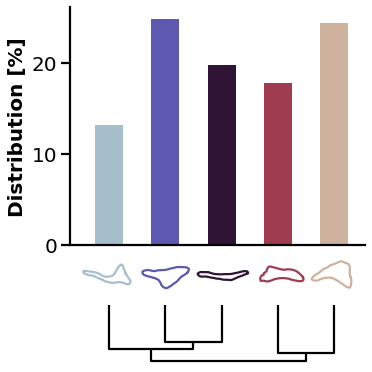

In [61]:
from pathlib import Path
import random
import shutil
import tempfile
import pandas as pd
import numpy as np
import pickle
from scipy.optimize import linear_sum_assignment

base_path = Path("/gscratch/cheme/nlsschim/data/cross_species/tifs/specific_studies/adult_wm_gm/")
all_files = list(base_path.rglob("*.tif"))

# Shuffle and split
random.seed(42)
shuffled_files = all_files.copy()
random.shuffle(shuffled_files)

k = 5
fold_size = len(shuffled_files) // k
folds = []
for i in range(k):
    start = i * fold_size
    end = start + fold_size if i < k - 1 else len(shuffled_files)
    folds.append(shuffled_files[start:end])

print(f"Total files: {len(all_files)}")
print(f"Fold sizes: {[len(f) for f in folds]}")

# Store predictions AND centroids
all_predictions = []
all_centroids = []

# Loop through all folds
for fold_idx in range(k):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_idx + 1}/{k}")
    print(f"{'='*60}")
    
    test_files = folds[fold_idx]
    train_files = [f for j, fold in enumerate(folds) if j != fold_idx for f in fold]
    
    print(f"Train: {len(train_files)}, Test: {len(test_files)}")
    
    # Create temp directories
    temp_dir = Path(tempfile.mkdtemp(prefix=f'vampire_fold{fold_idx}_'))
    train_dir = temp_dir / "train"
    test_dir = temp_dir / "test"
    train_dir.mkdir()
    test_dir.mkdir()
    
    # Copy files
    for f in train_files:
        shutil.copy2(f, train_dir / f.name)
    for f in test_files:
        shutil.copy2(f, test_dir / f.name)
    
    # Extract features
    print("Extracting features...")
    import vampire
    vampire.extraction.extract_properties(str(train_dir))
    
    # Train model
    print("Training model...")
    build_info_df = pd.DataFrame({
        'img_set_path': [str(train_dir)],
        'output_path': [str(train_dir)],
        'model_name': [f'model_fold{fold_idx}'],
        'num_points': [50],
        'num_clusters': [5],
        'num_pc': [np.nan]
    })
    vampire.quickstart.fit_models(build_info_df)
    
    # Find model and load centroids
    model_files = [f for f in train_dir.glob("*.pickle") if "model_" in f.name]
    model_path = model_files[0]
    
    # Load the model to get centroids
    with open(model_path, 'rb') as f:
        model = pickle.load(f)
    
    centroids = model.centroids
    print(f"Centroids shape: {centroids.shape}")
    all_centroids.append(centroids)
    
    # Apply to test set
    print("Applying to test set...")
    apply_info_df = pd.DataFrame({
        'img_set_path': [str(test_dir)],
        'model_path': [str(model_path)],
        'output_path': [str(test_dir)],
        'img_set_name': [f'fold{fold_idx}']
    })
    vampire.quickstart.transform_dataset(apply_info_df)
    
    # Load predictions
    pred_files = list(test_dir.glob("*apply*.csv"))
    if pred_files:
        pred_df = pd.read_csv(pred_files[0])
        pred_df['fold'] = fold_idx
        pred_df['original_shape_mode'] = pred_df['cluster_id']  # Keep original
        all_predictions.append(pred_df)
        print(f"✓ Collected {len(pred_df)} predictions")
    
    # Cleanup
    shutil.rmtree(temp_dir)

print(f"\n{'='*60}")
print("ALIGNING SHAPE MODES")
print(f"{'='*60}")

# Use fold 0 as reference
reference_centroids = all_centroids[0]
print(f"\nUsing fold 0 as reference")
print(f"Reference centroids shape: {reference_centroids.shape}")

# Align each fold to the reference
for fold_idx in range(k):
    if fold_idx == 0:
        print(f"Fold 0: Reference (no alignment needed)")
        continue
    
    fold_centroids = all_centroids[fold_idx]
    
    # Compute pairwise distances between reference and fold centroids
    distances = np.zeros((reference_centroids.shape[0], fold_centroids.shape[0]))
    for i, ref_centroid in enumerate(reference_centroids):
        for j, fold_centroid in enumerate(fold_centroids):
            distances[i, j] = np.linalg.norm(ref_centroid - fold_centroid)
    
    # Hungarian algorithm to find best matching
    row_ind, col_ind = linear_sum_assignment(distances)
    
    # Create mapping: old_mode -> new_mode
    mapping = {col_ind[i]: row_ind[i] for i in range(len(row_ind))}
    print(f"Fold {fold_idx}: Mapping {mapping}")
    
    # Remap shape modes in predictions
    pred_df = all_predictions[fold_idx]
    pred_df['shape_mode'] = pred_df['original_shape_mode'].map(mapping)

# Combine all predictions
print(f"\n{'='*60}")
print("COMBINING RESULTS")
print(f"{'='*60}")

final_predictions = pd.concat(all_predictions, ignore_index=True)

print(f"\nTotal predictions: {len(final_predictions)}")
print(f"Aligned shape mode distribution:")
print(final_predictions['shape_mode'].value_counts().sort_index())

# Save results
output_file = "cross_species_kfold_aligned_predictions.csv"
final_predictions.to_csv(output_file, index=False)
print(f"\n✓ Saved to: {output_file}")

print("\nDone! 🎉")

In [52]:
final_predictions

,filename,image_id,label,centroid-y,centroid-x,area,bbox_area,convex_area,filled_area,perimeter,...,euler_number,eccentricity,solidity,extent,circularity,aspect_ratio,cluster_id,plot_cluster_id,distance_to_centroid,fold
0,20230315_pig_sow2_B_60x_cc3_denoised_Alx568_ot...,0,1,276.167467,195.843200,1875.0,232068.0,138310.0,1875.0,1136.299603,...,11,0.656936,0.013557,0.008080,0.018248,1.326355,4,5,0.894300,0
1,20230203_mouse_saline_p45_ms6_slide9_slice3_60...,1,1,226.112815,247.143349,6976.0,244524.0,216017.0,6976.0,4528.403425,...,29,0.552607,0.032294,0.028529,0.004275,1.199844,0,1,0.469710,0
2,20230303_mouse_saline_p45_female_fs4_slide11_s...,2,1,365.645470,243.455824,1777.0,106080.0,69393.0,1777.0,1111.565584,...,8,0.783122,0.025608,0.016752,0.018073,1.608059,3,4,0.808461,0
3,20230212_mouse_saline_p45_ms4_slide14_slice_sl...,4,1,243.357776,255.873448,1691.0,181475.0,92449.0,1691.0,950.683333,...,5,0.808312,0.018291,0.009318,0.023512,1.698500,1,2,0.875695,0
4,20230301_mouse_saline_p45_female_fs6_slide14_s...,5,1,232.803198,340.389914,813.0,78411.0,40280.0,813.0,501.149278,...,4,0.966603,0.020184,0.010368,0.040679,3.902021,0,1,0.974009,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,20230302_mouse_saline_p45_female_fs4_slide11_s...,48,1,225.537669,360.129262,2522.0,216081.0,124027.0,2522.0,1533.087445,...,9,0.712943,0.020334,0.011672,0.013484,1.426082,1,2,0.822294,4
240,20230301_mouse_saline_p45_female_fs6_slide14_s...,49,1,422.419034,334.799716,704.0,38710.0,22317.0,704.0,363.492424,...,3,0.867773,0.031545,0.018187,0.066956,2.012229,4,5,0.889183,4
241,UWA-7197_A1_60X_Cortex_Image3_-_Denoised_RGB_A...,50,1,240.475448,245.492968,12443.0,236160.0,200257.0,12443.0,6379.626043,...,29,0.247478,0.062135,0.052689,0.003842,1.032105,3,4,0.830016,4
242,20230205_mouse_saline_p45_male_ms6_slide9_slic...,51,1,281.755683,200.188095,10601.0,227504.0,194430.0,10601.0,5673.983294,...,29,0.607834,0.054523,0.046597,0.004138,1.259345,4,5,0.941076,4


In [57]:
import pandas as pd
import numpy as np

# Load the predictions
df = pd.read_csv("cross_species_kfold_aligned_predictions.csv")

print("="*60)
print("K-FOLD CROSS-VALIDATION RESULTS")
print("="*60)

print(f"\nTotal predictions: {len(df)}")
print(f"Expected: 257 files")
print(f"Missing: {257 - len(df)} (probably failed processing)")

print("\n--- Aligned Shape Mode Distribution ---")
print(df['shape_mode'].value_counts().sort_index())

print("\n--- Original vs Aligned Comparison ---")
for fold in range(5):
    fold_df = df[df['fold'] == fold]
    print(f"\nFold {fold}:")
    print(f"  Original: {fold_df['original_shape_mode'].value_counts().sort_index().to_dict()}")
    print(f"  Aligned:  {fold_df['shape_mode'].value_counts().sort_index().to_dict()}")

# Extract species from filename
def extract_species(filename):
    name = filename.lower()
    if 'mouse' in name or 'ms' in name or 'fs' in name:
        return 'mouse'
    elif 'rat' in name:
        return 'rat'
    elif 'uwa' in name:
        return 'human'
    elif 'pig' in name or 'sow' in name:
        return 'pig'
    else:
        return 'unknown'

# Extract region from filename
def extract_region(filename):
    name = filename.lower()
    if 'corpus' in name or '_cc' in name:
        return 'corpus_callosum'
    elif 'cortex' in name or 'cor' in name:
        return 'cortex'
    else:
        return 'unknown'

# Add metadata
df['species'] = df['filename'].apply(extract_species)
df['region'] = df['filename'].apply(extract_region)

print("\n--- Shape Modes by Species ---")
species_modes = df.groupby(['species', 'shape_mode']).size().unstack(fill_value=0)
print(species_modes)

print("\n--- Shape Modes by Region ---")
region_modes = df.groupby(['region', 'shape_mode']).size().unstack(fill_value=0)
print(region_modes)

# Save enhanced version
df.to_csv("cross_species_kfold_aligned_predictions_enhanced.csv", index=False)
print("\n✓ Saved enhanced version with species/region metadata")

K-FOLD CROSS-VALIDATION RESULTS

Total predictions: 244
Expected: 257 files
Missing: 13 (probably failed processing)

--- Aligned Shape Mode Distribution ---
shape_mode
0.0    32
1.0    40
2.0    44
3.0    45
4.0    36
Name: count, dtype: int64

--- Original vs Aligned Comparison ---

Fold 0:
  Original: {0: 8, 1: 9, 2: 12, 3: 10, 4: 8}
  Aligned:  {}

Fold 1:
  Original: {0: 5, 1: 8, 2: 9, 3: 13, 4: 11}
  Aligned:  {0.0: 11, 1.0: 5, 2.0: 8, 3.0: 9, 4.0: 13}

Fold 2:
  Original: {0: 15, 1: 6, 2: 14, 3: 4, 4: 10}
  Aligned:  {0.0: 4, 1.0: 15, 2.0: 6, 3.0: 14, 4.0: 10}

Fold 3:
  Original: {0: 12, 1: 12, 2: 6, 3: 6, 4: 14}
  Aligned:  {0.0: 6, 1.0: 12, 2.0: 14, 3.0: 12, 4.0: 6}

Fold 4:
  Original: {0: 10, 1: 7, 2: 11, 3: 16, 4: 8}
  Aligned:  {0.0: 11, 1.0: 8, 2.0: 16, 3.0: 10, 4.0: 7}

--- Shape Modes by Species ---
shape_mode  0.0  1.0  2.0  3.0  4.0
species                            
human         8   12   10    9    9
mouse        14   13   19   18   12
pig           3    6    5   